# 04. Economics of the approval cut-off
Profit of the portfolio as a function of the approval rate, for the four models of stage 3.
Assumptions (decision 31): a repaid loan earns **margin = 10%** of its amount over its life,
a defaulted loan loses **LGD = 65%** of it; EAD = `AMT_CREDIT`. Break-even PD = 0.10 / 0.75 = 13.3%.
The model is an overlay on the current policy: clients are already approved, so *approve all* is the
baseline. The cut-off is chosen on **valid**; test is used once at the end (decision 30).
Amounts are in the currency of `AMT_CREDIT` (not specified in the dataset).

In [17]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.economics import (break_even_pd, client_profit, optimal_cutoff,
                           portfolio_at_pd_cutoff, profit_curve)
from src.viz import INK_MUTED, INK_SECONDARY, SERIES, apply_style, save_figure

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MARGIN, LGD = 0.10, 0.65
BREAK_EVEN = break_even_pd(MARGIN, LGD)

apply_style()
pd.set_option("display.max_columns", 30, "display.width", 200)

valid = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "valid_predictions.parquet")
assert len(valid) == 61_502

MODELS = {
    "scorecard_with_ext": "Scorecard (logreg on WoE), with EXT_SOURCE",
    "scorecard_no_ext": "Scorecard (logreg on WoE), no EXT_SOURCE",
    "lightgbm_with_ext": "LightGBM, with EXT_SOURCE",
    "lightgbm_no_ext": "LightGBM, no EXT_SOURCE",
}
y, ead = valid["TARGET"], valid["AMT_CREDIT"]
print(f"Break-even PD: {BREAK_EVEN:.1%}")

Break-even PD: 13.3%


## 4.3 Profit curves and the optimal cut-off (valid)

In [18]:
# Baseline: the current policy approves everyone in this sample
baseline_profit = client_profit(y, ead, MARGIN, LGD).sum()
baseline = {"clients": len(valid), "bad_rate": y.mean(), "loan_volume": ead.sum(),
            "profit": baseline_profit, "profit_to_volume": baseline_profit / ead.sum()}
pd.Series(baseline).round(4)

clients             6.150200e+04
bad_rate            8.070000e-02
loan_volume         3.688701e+10
profit              1.590172e+09
profit_to_volume    4.310000e-02
dtype: float64

In [19]:
curves = {key: profit_curve(valid[f"pd_{key}"], y, ead, MARGIN, LGD, step=0.005) for key in MODELS}

rows = []
for key in MODELS:
    best = optimal_cutoff(curves[key])
    rule = portfolio_at_pd_cutoff(valid[f"pd_{key}"], y, ead, BREAK_EVEN, MARGIN, LGD)
    rows.append({
        "model": key,
        # Empirical optimum: the approval rate with the highest realized profit on valid
        "opt_approval_rate": best["approval_rate"],
        "opt_pd_cutoff": best["pd_cutoff"],
        "opt_bad_rate": best["bad_rate"],
        "opt_profit": best["profit"],
        # Theoretical rule: approve if PD < break-even PD (relies on calibrated PD)
        "rule_approval_rate": rule["approval_rate"],
        "rule_bad_rate": rule["bad_rate"],
        "rule_profit": rule["profit"],
    })
economics = pd.DataFrame(rows).set_index("model")
economics["uplift_vs_baseline"] = economics["opt_profit"] - baseline_profit
economics["uplift_pct"] = economics["uplift_vs_baseline"] / baseline_profit
economics.round(4)

,opt_approval_rate,opt_pd_cutoff,opt_bad_rate,opt_profit,rule_approval_rate,rule_bad_rate,rule_profit,uplift_vs_baseline,uplift_pct
model,,,,,,,,,
scorecard_with_ext,0.775,0.1125,0.0471,1.924591e+09,0.8277,0.0527,1.906550e+09,3.344191e+08,0.2103
scorecard_no_ext,0.805,0.1186,0.0562,1.809521e+09,0.8465,0.0597,1.810083e+09,2.193484e+08,0.1379
lightgbm_with_ext,0.835,0.1357,0.0490,2.014191e+09,0.8309,0.0487,2.011680e+09,4.240186e+08,0.2666
lightgbm_no_ext,0.825,0.1269,0.0525,1.908500e+09,0.8387,0.0538,1.908416e+09,3.183273e+08,0.2002


In [20]:
# Score of the scorecard at its optimal cut-off: the number a credit officer would use
best_sc = optimal_cutoff(curves["scorecard_with_ext"])
approved = valid["pd_scorecard_with_ext"] <= best_sc["pd_cutoff"]
score_cutoff = valid.loc[approved, "score_scorecard_with_ext"].min()
print(f"Scorecard with EXT_SOURCE: approve clients with score >= {score_cutoff:.0f} "
      f"(PD <= {best_sc['pd_cutoff']:.1%}), approval rate {best_sc['approval_rate']:.1%}")

Scorecard with EXT_SOURCE: approve clients with score >= 547 (PD <= 11.2%), approval rate 77.5%


In [21]:
# Money: price of explainability and value of external scores, at each model's optimal cut-off
p = economics["opt_profit"]
money = pd.Series({
    "price_of_explainability_with_ext": p["lightgbm_with_ext"] - p["scorecard_with_ext"],
    "price_of_explainability_no_ext": p["lightgbm_no_ext"] - p["scorecard_no_ext"],
    "value_of_ext_scorecard": p["scorecard_with_ext"] - p["scorecard_no_ext"],
    "value_of_ext_lightgbm": p["lightgbm_with_ext"] - p["lightgbm_no_ext"],
})
# Break-even price of external scores per application: the extra profit they bring, spread over every
# client scored (all clients of the sample need a request, approved or not)
per_application = money[["value_of_ext_scorecard", "value_of_ext_lightgbm"]] / len(valid)
display(money.round(0))
per_application.round(1).rename("max price per request")

price_of_explainability_with_ext     89599539.0
price_of_explainability_no_ext       98978890.0
value_of_ext_scorecard              115070677.0
value_of_ext_lightgbm               105691327.0
dtype: float64

value_of_ext_scorecard    1871.0
value_of_ext_lightgbm     1718.5
Name: max price per request, dtype: float64

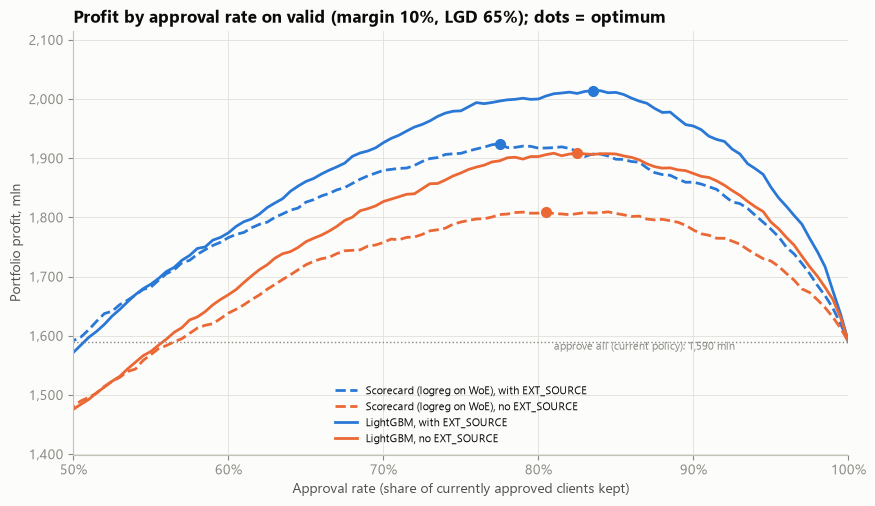

In [22]:
MLN = FuncFormatter(lambda v, _: f"{v / 1e6:,.0f}")
STYLE = {"scorecard": "--", "lightgbm": "-"}
COLOR = {"with_ext": SERIES[0], "no_ext": SERIES[1]}

fig, ax = plt.subplots(figsize=(10, 5.5))
for key, label in MODELS.items():
    model_type, version = key.split("_", 1)
    c = curves[key]
    ax.plot(c["approval_rate"], c["profit"], color=COLOR[version], linestyle=STYLE[model_type], label=label)
    best = optimal_cutoff(c)
    ax.plot(best["approval_rate"], best["profit"], "o", color=COLOR[version], markersize=7)
ax.axhline(baseline_profit, color=INK_MUTED, linestyle=":", linewidth=1)
ax.text(0.62, baseline_profit, f"approve all (current policy): {baseline_profit / 1e6:,.0f} mln",
        transform=ax.get_yaxis_transform(), va="top", fontsize=8, color=INK_MUTED)
ax.set_xlim(0.5, 1.0)
ax.set_ylim(baseline_profit * 0.88, economics["opt_profit"].max() * 1.05)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(MLN)
ax.set_xlabel("Approval rate (share of currently approved clients kept)")
ax.set_ylabel("Portfolio profit, mln")
ax.set_title(f"Profit by approval rate on valid (margin {MARGIN:.0%}, LGD {LGD:.0%}); dots = optimum")
ax.legend(loc="lower center", fontsize=8)

save_figure(fig, "04_profit_curve", FIGURES_DIR)
plt.show()

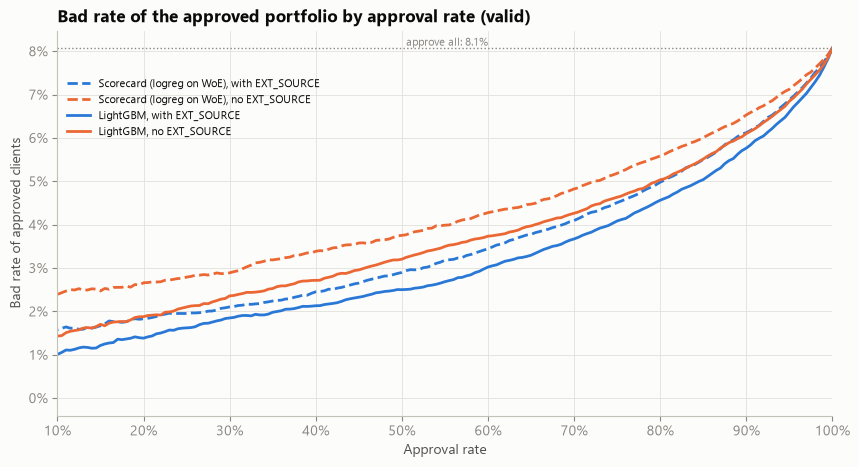

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
for key, label in MODELS.items():
    model_type, version = key.split("_", 1)
    c = curves[key]
    ax.plot(c["approval_rate"], c["bad_rate"], color=COLOR[version], linestyle=STYLE[model_type], label=label)
ax.axhline(y.mean(), color=INK_MUTED, linestyle=":", linewidth=1)
ax.text(0.45, y.mean(), f"approve all: {y.mean():.1%}", transform=ax.get_yaxis_transform(),
        va="bottom", fontsize=8, color=INK_MUTED)
ax.set_xlim(0.1, 1.0)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Approval rate")
ax.set_ylabel("Bad rate of approved clients")
ax.set_title("Bad rate of the approved portfolio by approval rate (valid)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9), fontsize=8)

save_figure(fig, "04_bad_rate_curve", FIGURES_DIR)
plt.show()

In [24]:
# Realized vs expected profit along the curve of the main model: close lines = PD can be trusted in money
c = curves["scorecard_with_ext"]
check = c.iloc[::20][["approval_rate", "profit", "expected_profit"]].assign(
    gap_pct=lambda t: (t["expected_profit"] - t["profit"]) / t["profit"].abs())
check.round(3)

,approval_rate,profit,expected_profit,gap_pct
0,0.005,2.291036e+07,2.657877e+07,0.160
20,0.105,4.337633e+08,4.569095e+08,0.053
40,0.205,7.894199e+08,8.170548e+08,0.035
60,0.305,1.107342e+09,1.128375e+09,0.019
80,0.405,1.384457e+09,1.402461e+09,0.013
100,0.505,1.598304e+09,1.634279e+09,0.023
120,0.605,1.771402e+09,1.822199e+09,0.029
140,0.705,1.881325e+09,1.956201e+09,0.040
160,0.805,1.917373e+09,2.021271e+09,0.054
180,0.905,1.856460e+09,1.985114e+09,0.069


### Why realized profit is below expected: larger loans default more often at the same PD
PD is calibrated by **number of clients**, but losses are counted in **money**. Within every PD decile,
defaulted loans are larger than repaid ones, so the amount-weighted bad rate exceeds the amount-weighted PD.
`AMT_CREDIT` left the scorecard by the sign rule (decision 27), so the model does not see this effect;
the empirical cut-off, chosen on realized money, is therefore stricter than the break-even PD rule.

In [25]:
p_col = "pd_scorecard_with_ext"
d = valid.assign(decile=pd.qcut(valid[p_col], 10, labels=False) + 1)
loan_size = d.groupby("decile").apply(lambda g: pd.Series({
    "mean_pd": g[p_col].mean(),
    "bad_rate_by_count": g["TARGET"].mean(),
    "bad_rate_by_amount": (g["TARGET"] * g["AMT_CREDIT"]).sum() / g["AMT_CREDIT"].sum(),
    "avg_loan_defaulted": g.loc[g["TARGET"] == 1, "AMT_CREDIT"].mean(),
    "avg_loan_repaid": g.loc[g["TARGET"] == 0, "AMT_CREDIT"].mean(),
}), include_groups=False)
loan_size.round(4)

,mean_pd,bad_rate_by_count,bad_rate_by_amount,avg_loan_defaulted,avg_loan_repaid
decile,,,,,
1,0.0121,0.0158,0.0175,866725.9330,781053.2341
2,0.0210,0.0208,0.0229,767959.8047,695300.8824
3,0.0292,0.0265,0.0276,680213.4294,653208.3888
4,0.0384,0.0350,0.0374,676945.6326,631015.6890
5,0.0491,0.0468,0.0538,688877.3125,595311.2088
6,0.0624,0.0616,0.0682,641153.7309,575257.9141
7,0.0799,0.0802,0.0892,620023.3996,552020.3249
8,0.1050,0.1117,0.1179,554878.0939,522205.7142
9,0.1464,0.1527,0.1579,523787.1565,503173.3377


## 4.4 Sensitivity to the assumptions
Margin and LGD are assumptions, not data. The whole analysis is repeated on a grid
LGD 45-85% x margin 6-14% to see which conclusions survive.

In [26]:
LGDS = [0.45, 0.55, 0.65, 0.75, 0.85]
MARGINS = [0.06, 0.08, 0.10, 0.12, 0.14]

sens_rows = []
for lgd in LGDS:
    for margin in MARGINS:
        base = client_profit(y, ead, margin, lgd).sum()
        opt = {key: optimal_cutoff(profit_curve(valid[f"pd_{key}"], y, ead, margin, lgd)) for key in MODELS}
        sens_rows.append({
            "lgd": lgd,
            "margin": margin,
            "break_even_pd": break_even_pd(margin, lgd),
            "approve_all_profit": base,
            "approval_rate": opt["scorecard_with_ext"]["approval_rate"],
            "scorecard_profit": opt["scorecard_with_ext"]["profit"],
            "uplift": opt["scorecard_with_ext"]["profit"] - base,
            "value_of_ext": opt["scorecard_with_ext"]["profit"] - opt["scorecard_no_ext"]["profit"],
            "price_of_explainability": opt["lightgbm_with_ext"]["profit"] - opt["scorecard_with_ext"]["profit"],
        })
sens = pd.DataFrame(sens_rows)

summary = pd.Series({
    "approve_all_loss_making_cells": int((sens["approve_all_profit"] < 0).sum()),
    "uplift_always_positive": bool((sens["uplift"] > 0).all()),
    "value_of_ext_always_positive": bool((sens["value_of_ext"] > 0).all()),
    "price_of_explainability_always_positive": bool((sens["price_of_explainability"] > 0).all()),
    "approval_rate_min": sens["approval_rate"].min(),
    "approval_rate_max": sens["approval_rate"].max(),
})
display(summary)
sens.assign(**{c: sens[c] / 1e6 for c in ["approve_all_profit", "scorecard_profit", "uplift",
                                          "value_of_ext", "price_of_explainability"]}).round(3)

approve_all_loss_making_cells                     2
uplift_always_positive                         True
value_of_ext_always_positive                   True
price_of_explainability_always_positive        True
approval_rate_min                          0.519999
approval_rate_max                          0.934994
dtype: object

,lgd,margin,break_even_pd,approve_all_profit,approval_rate,scorecard_profit,uplift,value_of_ext,price_of_explainability
0,0.45,0.06,0.118,786.221,0.770,1067.836,281.615,82.912,56.882
1,0.45,0.08,0.151,1468.001,0.815,1649.354,181.354,66.692,70.733
2,0.45,0.10,0.182,2149.780,0.915,2274.647,124.867,54.572,61.134
3,0.45,0.12,0.211,2831.559,0.935,2923.090,91.531,47.278,54.314
4,0.45,0.14,0.237,3513.339,0.935,3579.572,66.233,40.587,51.125
5,0.55,0.06,0.098,506.417,0.700,938.004,431.587,97.093,67.729
6,0.55,0.08,0.127,1188.197,0.775,1496.200,308.003,99.691,69.768
7,0.55,0.10,0.154,1869.976,0.840,2082.209,212.233,77.952,87.730
8,0.55,0.12,0.179,2551.756,0.915,2708.216,156.460,67.128,76.837
9,0.55,0.14,0.203,3233.535,0.915,3355.397,121.862,61.196,67.996


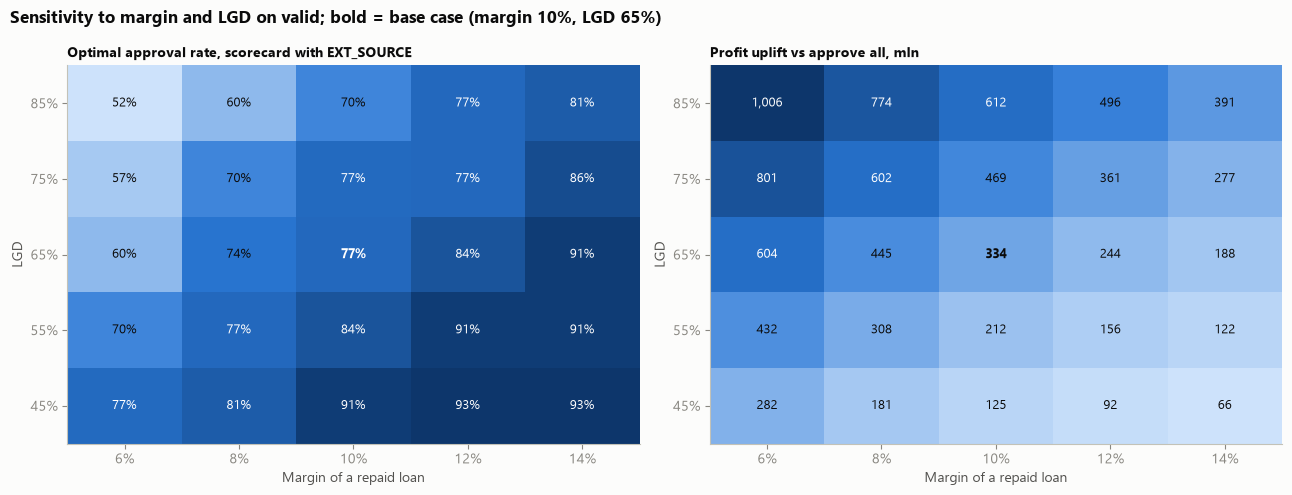

In [27]:
from matplotlib.colors import LinearSegmentedColormap

SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])


def heatmap(ax, column: str, fmt, title: str):
    grid = sens.pivot(index="lgd", columns="margin", values=column).sort_index(ascending=False)
    im = ax.imshow(grid, cmap=SEQUENTIAL, aspect="auto")
    ax.set_xticks(range(len(grid.columns)), [f"{m:.0%}" for m in grid.columns])
    ax.set_yticks(range(len(grid.index)), [f"{l:.0%}" for l in grid.index])
    ax.set_xlabel("Margin of a repaid loan")
    ax.set_ylabel("LGD")
    ax.grid(False)
    lo, hi = grid.values.min(), grid.values.max()
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            dark = (v - lo) / (hi - lo + 1e-12) > 0.55
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=9,
                    color="#ffffff" if dark else "#0b0b0b",
                    fontweight="bold" if (grid.index[i] == LGD and grid.columns[j] == MARGIN) else "normal")
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
heatmap(axes[0], "approval_rate", lambda v: f"{v:.0%}", "Optimal approval rate, scorecard with EXT_SOURCE")
heatmap(axes[1], "uplift", lambda v: f"{v / 1e6:,.0f}", "Profit uplift vs approve all, mln")
fig.suptitle("Sensitivity to margin and LGD on valid; bold = base case (margin 10%, LGD 65%)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()

save_figure(fig, "04_sensitivity", FIGURES_DIR)
plt.show()

In [28]:
# Margin is not observed: it is yield minus funding cost minus operating cost over the loan's life.
# Scenario: funding becomes 3 pp more expensive -> margin 10% -> 7% (average life of about one year)
scenarios = {"base": (0.10, LGD), "funding +3 pp": (0.07, LGD), "collection worse, LGD +10 pp": (0.10, 0.75),
             "both": (0.07, 0.75)}
rows = []
for name, (margin, lgd) in scenarios.items():
    base = client_profit(y, ead, margin, lgd).sum()
    best = optimal_cutoff(profit_curve(valid["pd_scorecard_with_ext"], y, ead, margin, lgd))
    rows.append({"scenario": name, "margin": margin, "lgd": lgd, "break_even_pd": break_even_pd(margin, lgd),
                 "approval_rate": best["approval_rate"], "pd_cutoff": best["pd_cutoff"],
                 "approve_all_profit_mln": base / 1e6, "scorecard_profit_mln": best["profit"] / 1e6,
                 "uplift_mln": (best["profit"] - base) / 1e6})
pd.DataFrame(rows).set_index("scenario").round(3)

,margin,lgd,break_even_pd,approval_rate,pd_cutoff,approve_all_profit_mln,scorecard_profit_mln,uplift_mln
scenario,,,,,,,,
base,0.10,0.65,0.133,0.775,0.112,1590.172,1924.591,334.419
funding +3 pp,0.07,0.65,0.097,0.700,0.091,567.503,1084.456,516.953
"collection worse, LGD +10 pp",0.10,0.75,0.118,0.770,0.111,1310.369,1779.727,469.359
both,0.07,0.75,0.085,0.600,0.070,287.699,976.530,688.830
